# Grading Like the Experts

The experiment behind the findings page. Five LLM judges grade 799 BFF-Bench answers twice: once with a standard grading prompt, and once with the five rules Kensho's experts used to make the labels (No Free Labels, appendix A.4). The answers are every BFF-Bench answer where at least 2 of 3 experts agree, scored against the majority vote. One conversation is left out, because its VERDICTS record stores the reference where the question should be.

| Prompt | What the judge is told |
|---|---|
| `STD` | The standard grading prompt: decide whether the final answer is correct ([standard.md](../prompts/standard.md)) |
| `GUIDE` | The experts' five rules ([experts_rules.md](../prompts/experts_rules.md)) |
| `GUIDE_NO2` | The rules without rule 2, "steps disagree: incorrect", for the two gpt-oss judges ([experts_rules_without_rule_2.md](../prompts/experts_rules_without_rule_2.md)) |

Every verdict is saved in `runs/`, so a rerun grades only what is missing. As shipped, nothing is missing, so the notebook makes no API calls and needs no keys. Section 4 writes the tables to `results/` and the charts to `results/figures/`.

## 1. Settings

In [1]:
import pathlib
# the grading_like_experts folder: this notebook's parent, or the folder it is run from
ROOT = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "data").is_dir() and (p / "runs").is_dir())
OUT = ROOT / "runs"
MOCK = False                                               # True: fake verdicts, no API calls
BUDGET = dict(openrouter=2.00, modal=90.00, openai=10.00)  # $ caps for this notebook
OPENROUTER_RESERVE = 0.10                                  # never take the OpenRouter key below this
MODAL_TOTAL_CAP = 450.0                                    # Modal spend across all runs stays under your credits

JUDGES = [
    dict(name="qwen3.7-flash", backend="openrouter", model="qwen/qwen3.7-flash", reasoning={"effort": "low"}, est_cost=0.0003, arms=["STD", "GUIDE"]),
    dict(name="gpt-4.1-mini",  backend="openai",     model="gpt-4.1-mini", est_cost=0.0015, arms=["STD", "GUIDE"]),
    dict(name="deepseek-v3.1", backend="openrouter", model="deepseek/deepseek-chat-v3.1", est_cost=0.0007, arms=["STD", "GUIDE"]),
    dict(name="gpt-oss-20b",   backend="modal",      model="openai/gpt-oss-20b",  gpu="L40S", max_hours=0.75, arms=["STD", "GUIDE", "GUIDE_NO2"]),
    dict(name="gpt-oss-120b",  backend="modal",      model="openai/gpt-oss-120b", gpu="H100", max_hours=1.0,  arms=["STD", "GUIDE", "GUIDE_NO2"]),
]
NOISE_JUDGE = "qwen3.7-flash"   # grades STD twice, to measure rerun noise
TEMPERATURE, MAX_TOKENS, WORKERS = 0.0, 4096, 24

In [2]:
# ======================= plumbing: keys, budget guardrails, model clients, caching (no need to read) =======================
import os, json, time, re, random, threading, collections, requests
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd

# keys come from a .env file in the grading_like_experts folder (copy .env.example); only needed to grade new verdicts
env = ROOT / ".env"
for line in (env.read_text().splitlines() if env.exists() else []):
    k, _, v = line.partition("="); k, v = k.strip(), v.split("#")[0].strip()
    if k and not k.startswith("#") and v: os.environ.setdefault(k, v)

def run_file(name):
    # runs/<judge>__<prompt>.jsonl; inside each row the arm is still written "<judge>|<prompt>"
    return OUT / f"{name.replace('|', '__')}.jsonl"

class BudgetStop(RuntimeError): pass

class Guard:
    # Spend is kept in runs/spend.json (this notebook) and .spend/modal_total.json (Modal); a call that would pass a cap is refused.
    def __init__(self):
        self.path, self.lock = OUT / "spend.json", threading.Lock()
        self.spent = json.loads(self.path.read_text()) if self.path.exists() else {"openrouter": 0.0, "modal": 0.0, "openai": 0.0}
        self.modal_file = ROOT / ".spend/modal_total.json"
    def or_left(self):
        if MOCK: return 999.0
        d = requests.get("https://openrouter.ai/api/v1/key", headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"}, timeout=30).json()["data"]
        return (d["limit"] - d["usage"]) if d.get("limit") is not None else 1e9
    def modal_total(self): return json.loads(self.modal_file.read_text())["total"] if self.modal_file.exists() else 0.0
    def check(self, provider, est):
        if self.spent[provider] + est > BUDGET[provider]:
            raise BudgetStop(f"{provider}: ${self.spent[provider] + est:.2f} would pass this notebook's ${BUDGET[provider]:.2f} cap")
        if provider == "openrouter" and self.or_left() - est < OPENROUTER_RESERVE:
            raise BudgetStop(f"openrouter: keeping ${OPENROUTER_RESERVE:.2f} of credit on the key")
        if provider == "modal" and self.modal_total() + est > MODAL_TOTAL_CAP:
            raise BudgetStop(f"modal: total spend would pass ${MODAL_TOTAL_CAP:.0f}")
    def add(self, provider, cost):
        with self.lock:
            self.spent[provider] += float(cost or 0); self.path.write_text(json.dumps(self.spent, indent=1))
            if provider == "modal":
                self.modal_file.parent.mkdir(exist_ok=True); self.modal_file.write_text(json.dumps({"total": self.modal_total() + float(cost or 0)}))
    def report(self): print("spent by this notebook:", {k: round(v, 2) for k, v in self.spent.items()}, "| caps:", BUDGET)
guard = Guard()

def parse_verdict(text):
    m = re.findall(r"VERDICT:\s*\**\s*(CORRECT|INCORRECT)", text or "", flags=re.I)
    return (1 if m[-1].upper() == "CORRECT" else 0) if m else -1

def _post(url, body, key):
    for attempt in range(6):
        try:
            r = requests.post(url, timeout=300, json=body, headers={"Authorization": f"Bearer {key}"})
        except requests.RequestException:
            time.sleep(3 * (attempt + 1)); continue
        if r.status_code == 400 and "max_tokens" in r.text and "max_tokens" in body:     # newer OpenAI models want max_completion_tokens
            body["max_completion_tokens"] = body.pop("max_tokens"); body.pop("temperature", None); continue
        if r.status_code in (408, 429, 500, 502, 503, 504): time.sleep(3 * (attempt + 1)); continue
        if r.status_code != 200: return None, f"HTTP {r.status_code}: {r.text[:200]}"
        d = r.json()
        if d.get("choices"): return d, None
        time.sleep(3 * (attempt + 1))
    return None, "gave up after retries"

def openrouter_call(model, messages, max_tokens, temperature, reasoning=None):
    body = {"model": model, "messages": messages, "max_tokens": max_tokens, "temperature": temperature, "usage": {"include": True}}
    if reasoning: body["reasoning"] = reasoning
    d, err = _post("https://openrouter.ai/api/v1/chat/completions", body, os.environ["OPENROUTER_API_KEY"])
    if err: return dict(text="", error=err, cost=0.0)
    c, u = d["choices"][0], d.get("usage") or {}
    return dict(text=c["message"].get("content") or "", finish=c.get("finish_reason"), cost=float(u.get("cost") or 0),
                served=d.get("model"), host=d.get("provider"), n_out=u.get("completion_tokens"))

OPENAI_PRICE = {"gpt-4.1-mini": (0.4, 1.6)}   # $ per million tokens (in, out), to estimate cost from tokens
def openai_call(model, messages, max_tokens, temperature):
    url = os.environ.get("OPENAI_BASE_URL", "https://api.openai.com/v1").rstrip("/") + "/chat/completions"
    d, err = _post(url, {"model": model, "messages": messages, "max_tokens": max_tokens, "temperature": temperature}, os.environ["OPENAI_API_KEY"])
    if err: return dict(text="", error=err, cost=0.0)
    c, u, served = d["choices"][0], d.get("usage") or {}, d.get("model", model)
    pin, pout = next((v for k, v in OPENAI_PRICE.items() if k in served), (2.5, 10.0))
    return dict(text=c["message"].get("content") or "", finish=c.get("finish_reason"), served=served, n_out=u.get("completion_tokens"),
                cost=(u.get("prompt_tokens", 0) * pin + u.get("completion_tokens", 0) * pout) / 1e6)

GPU_PRICE = {"L40S": 1.95, "H100": 3.95}   # Modal $ per hour
_modal = {}
def modal_generate(model_id, conversations, gpu, temperature, max_tokens, max_hours):
    # vLLM on one Modal GPU; weights cached in the 'hf-weights' volume. The image's Python must match this kernel's (functions are serialized).
    import modal, sys
    if not _modal:
        image = (modal.Image.debian_slim(python_version=f"{sys.version_info.major}.{sys.version_info.minor}")
                 .pip_install("vllm>=0.10.2", "huggingface_hub[hf_transfer]>=0.34")
                 .env({"HF_HUB_ENABLE_HF_TRANSFER": "1", "VLLM_USE_FLASHINFER_SAMPLER": "0", "VLLM_USE_DEEP_GEMM": "0"}))
        vol = modal.Volume.from_name("hf-weights", create_if_missing=True)
        def gen(model_id, conversations, temperature, max_tokens):
            from vllm import LLM, SamplingParams
            llm = LLM(model=model_id, max_model_len=16000, gpu_memory_utilization=0.90, trust_remote_code=True)
            outs = llm.chat(conversations, SamplingParams(temperature=temperature, max_tokens=max_tokens), use_tqdm=False)
            return [dict(text=o.outputs[0].text, finish=o.outputs[0].finish_reason, n_out=len(o.outputs[0].token_ids)) for o in outs]
        _modal["app"] = modal.App("grading-like-experts")
        for g in GPU_PRICE:
            _modal[g] = _modal["app"].function(image=image, gpu=g, volumes={"/root/.cache/huggingface": vol}, timeout=3 * 3600,
                                               serialized=True, name=f"gen_{g.lower()}")(gen)
    guard.check("modal", GPU_PRICE[gpu] * max_hours)
    t0 = time.time(); print(f"  Modal {gpu}: {model_id}, {len(conversations)} prompts (a few minutes to start)...", flush=True)
    try:
        with _modal["app"].run():
            return _modal[gpu].remote(model_id, conversations, temperature, max_tokens)
    finally:
        guard.add("modal", GPU_PRICE[gpu] * (time.time() - t0) / 3600)

def _done(path):
    # rows already graded; failed calls are dropped from the file so they are retried
    if not path.exists(): return set()
    rows = [json.loads(l) for l in path.read_text().splitlines()]
    if any(r.get("error") for r in rows): path.write_text("".join(json.dumps(r) + "\n" for r in rows if not r.get("error")))
    return {(r["item_id"], r["run"]) for r in rows if not r.get("error")}

def _row(arm, it, r, o):
    return json.dumps(dict(arm=arm, item_id=it["item_id"], run=r, verdict=parse_verdict(o.get("text")), finish=o.get("finish"), served=o.get("served"),
                           host=o.get("host"), cost=o.get("cost"), error=o.get("error"), n_out=o.get("n_out"), text=(o.get("text") or "")[-4000:])) + "\n"

def run_arm(arm, items, make_messages):
    # one API judge x prompt: graded in chunks, cost projected from real usage, every verdict appended to its run file
    path = run_file(arm["name"]); done = _done(path)
    todo = [(it, r) for it in items for r in range(arm["runs"]) if (it["item_id"], r) not in done]
    if not todo: print(f"{arm['name']:24s} cached ({len(done)} rows)"); return
    prov, est, n0, t0 = ("openrouter" if arm["backend"] == "openrouter" else "openai"), arm["est_cost"], len(todo), time.time()
    call = (lambda it: openrouter_call(arm["model"], make_messages(it), arm["max_tokens"], arm["temperature"], arm.get("reasoning"))) if prov == "openrouter" \
        else (lambda it: openai_call(arm["model"], make_messages(it), arm["max_tokens"], arm["temperature"]))
    try:
        with open(path, "a") as f:
            while todo:
                chunk, todo = todo[:2 * WORKERS], todo[2 * WORKERS:]
                guard.check(prov, est * (len(chunk) + len(todo)))
                if MOCK:
                    outs = [dict(text=f"VERDICT: {'CORRECT' if (it['gold'] if random.random() < .8 else 1 - it['gold']) else 'INCORRECT'}", cost=0.0) for it, _ in chunk]
                else:
                    with ThreadPoolExecutor(WORKERS) as ex: outs = list(ex.map(lambda x: call(x[0]), chunk))
                for (it, r), o in zip(chunk, outs): guard.add(prov, o.get("cost")); f.write(_row(arm["name"], it, r, o))
                est = max(np.mean([o.get("cost") or 0 for o in outs]), 1e-6)
    except BudgetStop as e:
        print(f"STOPPED {arm['name']}: {e} (rows so far are kept)")
    print(f"{arm['name']:24s} +{n0 - len(todo)} rows in {time.time() - t0:.0f}s")

def run_modal_group(group, items):
    # all prompts of one Modal judge in one GPU session (one weight load)
    convs, slots = [], []
    for arm, mk in group:
        done = _done(run_file(arm["name"]))
        for it in items:
            for r in range(arm["runs"]):
                if (it["item_id"], r) not in done: convs.append(mk(it)); slots.append((arm, it, r))
    if not convs: print("cached:", ", ".join(a["name"] for a, _ in group)); return
    a0 = group[0][0]
    if MOCK: outs = [dict(text=f"VERDICT: {'CORRECT' if it['gold'] else 'INCORRECT'}") for _, it, _ in slots]
    else:
        try: outs = modal_generate(a0["model"], convs, a0["gpu"], a0["temperature"], a0["max_tokens"], a0["max_hours"])
        except BudgetStop as e: print("STOPPED", a0["model"], e); return
    for (arm, it, r), o in zip(slots, outs):
        with open(run_file(arm["name"]), "a") as f: f.write(_row(arm["name"], it, r, dict(o, served=a0["model"], host="modal")))
    print(f"{a0['model']}: {len(convs)} verdicts for {len(group)} prompts")
guard.report()

spent by this notebook: {'openrouter': 0.0, 'modal': 0.0, 'openai': 0.0} | caps: {'openrouter': 2.0, 'modal': 90.0, 'openai': 10.0}


## 2. Answers and prompts

In [3]:
# Kensho's public data (kensho/VERDICTS and kensho/BFFBench on Hugging Face, saved in data/): three expert votes per answer, one reference per question turn
V = pd.read_parquet(ROOT / "data/verdicts.parquet"); V = V[V.dataset == "bffbench"]
REFS = {str(r.uid): [str(x) for x in r.references] for r in pd.read_parquet(ROOT / "data/bffbench.parquet").itertuples()}
votes = V.groupby(["cid", "turn"]).label.agg(list)
items = []
for r in V.groupby(["cid", "turn"]).first().reset_index().itertuples():
    c = collections.Counter(votes[(r.cid, r.turn)]); C, I = c["Correct"], c["Incorrect"]
    if max(C, I) < 2 or r.qid == "fc9858ab": continue        # at least 2 of 3 experts agree; fc9858ab stores its reference as the question
    items.append(dict(item_id=f"{r.cid}-t{r.turn}", qid=r.qid, gold=int(C > I), ref=REFS[str(r.qid)][int(r.turn) - 1],
                      group="all 3 agree" if max(C, I) == 3 else ("2 agree + 1 not sure" if min(C, I) == 0 else "2-1 split"),
                      conv=[{"role": m["role"], "content": m["content"]} for m in r.conv]))
GOLD, QID, GROUP = ({it["item_id"]: it[k] for it in items} for k in ("gold", "qid", "group"))
print(len(items), "answers from", len(set(QID.values())), "conversations:", dict(collections.Counter(GROUP.values())), "| share correct:", round(np.mean(list(GOLD.values())), 3))

# The three system prompts, word for word as in prompts/
RULES = ["If the assistant's final answer or recommendation disagrees with the reference, it is INCORRECT.",
         "If it agrees with the reference but its intermediate steps disagree with the reference, it is INCORRECT.",
         "If it agrees with the reference, its intermediate steps agree, and any additional information it provides is not obviously wrong based on the reference, it is CORRECT.",
         "If it agrees with the reference and its steps agree but the answer is slightly off due to rounding or approximate calculation, it is CORRECT.",
         "If it agrees with the reference and its steps agree but it lacks some information given in the reference, decide whether the missing information is crucial to the answer; if you are unsure, lean towards CORRECT."]
RULES_NO2 = ["If the assistant's final answer or recommendation disagrees with the reference, it is INCORRECT.",
             "If it agrees with the reference and any additional information it provides is not obviously wrong based on the reference, it is CORRECT.",
             "If it agrees with the reference but the answer is slightly off due to rounding or approximate calculation, it is CORRECT.",
             "If it agrees with the reference but lacks some information given in the reference, decide whether the missing information is crucial to the answer; if you are unsure, lean towards CORRECT."]
END = " Think it through briefly, then end with exactly one line: VERDICT: CORRECT or VERDICT: INCORRECT."
HEAD = ("You are an expert finance and accounting grader applying the benchmark's expert annotation guidelines. Grade only with respect to the EXPERT "
        "REFERENCE ANSWER, which has been verified by experts; grade as if the reference is correct even if you suspect an error in it. Rules: ")
rules = lambda rs: " ".join(f"({i}) {t}" for i, t in enumerate(rs, 1))  # noqa: E731
PROMPTS = {
    "STD": ("You are an expert finance and accounting grader. Read the conversation and decide whether the assistant's FINAL response correctly answers "
            "the user's final question. Key facts, calculations, numbers and conclusions must be correct; wording and formatting do not matter." + END),
    "GUIDE": HEAD + rules(RULES) + END,
    "GUIDE_NO2": HEAD + rules(RULES_NO2) + END,
}
USER_TEMPLATE = ("CONVERSATION:\n\n{convo}\n\nEXPERT REFERENCE ANSWER for the final question (treat as ground truth):\n{ref}\n\n"
                 "Grade the FINAL assistant response. End with VERDICT: CORRECT or VERDICT: INCORRECT.")

def maker(arm):
    def messages(it):
        convo = "\n\n".join(f"[{m['role'].upper()}]\n{m['content']}" for m in it["conv"])
        return [{"role": "system", "content": PROMPTS[arm]}, {"role": "user", "content": USER_TEMPLATE.format(convo=convo, ref=it["ref"])}]
    return messages

799 answers from 79 conversations: {'all 3 agree': 456, '2 agree + 1 not sure': 228, '2-1 split': 115} | share correct: 0.564


## 3. Grade

Spends only on verdicts not yet in `runs/`. As shipped, every verdict is there, so this prints that nothing is left to grade.

In [4]:
SPECS = [dict(j, name=f"{j['name']}|{a}", arm=a, runs=2 if (a == "STD" and j["name"] == NOISE_JUDGE) else 1, temperature=TEMPERATURE, max_tokens=MAX_TOKENS)
         for j in JUDGES for a in j["arms"]]
todo = {s["name"]: len(items) * s["runs"] - len(_done(run_file(s["name"]))) for s in SPECS}
print("verdicts still to grade:", {k: v for k, v in todo.items() if v} or "none, everything is cached")
for j in JUDGES:
    sp = [s for s in SPECS if s["name"].startswith(j["name"] + "|")]
    if j["backend"] == "modal": run_modal_group([(s, maker(s["arm"])) for s in sp], items)
    else:
        for s in sp: run_arm(s, items, maker(s["arm"]))
guard.report()

verdicts still to grade: none, everything is cached
qwen3.7-flash|STD        cached (1598 rows)
qwen3.7-flash|GUIDE      cached (799 rows)
gpt-4.1-mini|STD         cached (799 rows)
gpt-4.1-mini|GUIDE       cached (799 rows)
deepseek-v3.1|STD        cached (799 rows)
deepseek-v3.1|GUIDE      cached (799 rows)
cached: gpt-oss-20b|STD, gpt-oss-20b|GUIDE, gpt-oss-20b|GUIDE_NO2
cached: gpt-oss-120b|STD, gpt-oss-120b|GUIDE, gpt-oss-120b|GUIDE_NO2
spent by this notebook: {'openrouter': 0.0, 'modal': 0.0, 'openai': 0.0} | caps: {'openrouter': 2.0, 'modal': 90.0, 'openai': 10.0}


## 4. Results

Every number comes from `lib/juries.py`, the same code behind the findings page. Agreement is Cohen's κ against the expert labels, with 95% intervals from resampling the 79 conversations. False accepts are wrong answers the judge called correct, and false rejects are correct answers it called wrong. An unparsed verdict counts as the wrong one.

In [5]:
import sys
sys.path.insert(0, str(ROOT))
from lib import juries as J
A = J.annotator()                                   # cached in .cache/ until a run file changes
ORDER, GROUPS = J.ANNO_JUDGES, J.GROUPS             # judges most lenient first; vote groups
RES = ROOT / "results"; FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# cost per graded answer: what the API charged (gpt-4.1-mini estimated from its tokens), or for the self-hosted gpt-oss judges,
# their tokens at OpenRouter's list price on Oct 15, 2026: about 4 characters per input token, and the recorded output tokens
PRICE = {"gpt-oss-120b": (0.15, 0.60), "gpt-oss-20b": (0.018, 0.09)}   # $ per million tokens (in, out)
def cost(judge, arm):
    c = A["cells"][f"{judge}|{arm}"]
    if judge in PRICE: return ((A["prompt_chars"] + len(PROMPTS[arm])) / 4 * PRICE[judge][0] + c["n_out"] * PRICE[judge][1]) / 1e6
    return c["cost"]

ci = lambda t, f="{:+.3f}": f"{f.format(t[0])} [{t[1]:+.2f}, {t[2]:+.2f}]"  # noqa: E731
K = pd.DataFrame([{"judge": j, "prompt": a, "κ": A["cells"][f"{j}|{a}"]["kappa"][0],
                   "95% interval": "[{:.2f}, {:.2f}]".format(*A["cells"][f"{j}|{a}"]["kappa"][1:]),
                   "false accepts": A["cells"][f"{j}|{a}"]["fpr"], "false rejects": A["cells"][f"{j}|{a}"]["fnr"],
                   "parsed": A["cells"][f"{j}|{a}"]["parsed"], "$ per 1,000 answers": cost(j, a) * 1000}
                  for j in ORDER for a in ("STD", "GUIDE", "GUIDE_NO2") if f"{j}|{a}" in A["cells"]]).set_index(["judge", "prompt"])
print(f"{A['n_items']} answers from {A['n_questions']} conversations:", {GROUPS[g]: n for g, n in A["groups"].items()})
display(K.style.format({"κ": "{:.3f}", "false accepts": "{:.1%}", "false rejects": "{:.1%}", "parsed": "{:.1%}", "$ per 1,000 answers": "${:.2f}"}))

799 answers from 79 conversations: {'all 3 agree': 456, '2 agree + 1 not sure': 228, '2-1 split': 115}


In [6]:
# Rules minus standard prompt, per judge: all 799 answers and each group of expert votes (paired on the same answers)
P = pd.DataFrame([{"judge": j, "all answers": ci(A["deltas"][f"{j}|GUIDE-STD"]["orig"]),
                   **{f"{GROUPS[g]} ({A['groups'][g]})": ci(A["deltas_by_group"][f"{j}|GUIDE-STD"][g]) for g in GROUPS}} for j in ORDER]).set_index("judge")
display(P)

,all answers,all 3 agree (456),2 agree + 1 not sure (228),2-1 split (115)
judge,,,,
qwen3.7-flash,"+0.067 [+0.01, +0.12]","+0.095 [+0.03, +0.17]","+0.021 [-0.08, +0.12]","+0.054 [-0.09, +0.20]"
gpt-4.1-mini,"+0.075 [+0.02, +0.13]","+0.104 [+0.04, +0.17]","+0.081 [-0.01, +0.18]","-0.048 [-0.17, +0.07]"
deepseek-v3.1,"+0.049 [+0.01, +0.09]","+0.053 [+0.01, +0.10]","+0.058 [-0.03, +0.15]","+0.016 [-0.11, +0.14]"
gpt-oss-20b,"-0.035 [-0.09, +0.03]","-0.041 [-0.11, +0.04]","-0.040 [-0.15, +0.08]","+0.005 [-0.15, +0.16]"
gpt-oss-120b,"-0.074 [-0.12, -0.03]","-0.042 [-0.10, +0.02]","-0.139 [-0.23, -0.05]","-0.066 [-0.18, +0.05]"


In [7]:
# The two gpt-oss judges without rule 2
display(pd.DataFrame([{"judge": j, "standard": f"{A['cells'][f'{j}|STD']['kappa'][0]:.3f}", "all 5 rules": f"{A['cells'][f'{j}|GUIDE']['kappa'][0]:.3f}",
                       "rules without rule 2": f"{A['cells'][f'{j}|GUIDE_NO2']['kappa'][0]:.3f}",
                       "without rule 2 minus rules": ci(A["deltas"][f"{j}|GUIDE_NO2-GUIDE"]["orig"]),
                       "without rule 2 minus standard": ci(A["deltas"][f"{j}|GUIDE_NO2-STD"]["orig"])} for j in ("gpt-oss-20b", "gpt-oss-120b")]).set_index("judge"))
n = A["noise"]
print(f"Rerun noise ({NOISE_JUDGE}, standard prompt twice): {n['flip']:.1%} of verdicts change, κ {n['k0']:.3f} against {n['k1']:.3f}")

,standard,all 5 rules,rules without rule 2,without rule 2 minus rules,without rule 2 minus standard
judge,,,,,
gpt-oss-20b,0.694,0.658,0.692,"+0.034 [+0.00, +0.06]","-0.001 [-0.06, +0.06]"
gpt-oss-120b,0.728,0.654,0.710,"+0.056 [+0.03, +0.08]","-0.018 [-0.06, +0.03]"


Rerun noise (qwen3.7-flash, standard prompt twice): 7.0% of verdicts change, κ 0.671 against 0.682


In [8]:
# Write the three tables to results/
rows = []
for key in sorted(A["cells"]):
    j, a = key.split("|"); c = A["cells"][key]
    rows.append(dict(judge=j, prompt=a, answers="all", n=c["n"], kappa=c["kappa"][0], kappa_lo=c["kappa"][1], kappa_hi=c["kappa"][2],
                     false_accept=c["fpr"], false_reject=c["fnr"], parsed=c["parsed"], cost_per_1000=np.nan if j in PRICE else c["cost"] * 1000))
    for g in sorted(A["by_group"][key]):
        s = A["by_group"][key][g]
        rows.append(dict(judge=j, prompt=a, answers=GROUPS[g], n=s["n"], kappa=s["kappa"][0], kappa_lo=s["kappa"][1], kappa_hi=s["kappa"][2],
                         false_accept=s["fpr"], false_reject=s["fnr"], parsed=np.nan, cost_per_1000=np.nan))
pd.DataFrame(rows).round(4).to_csv(RES / "results_by_judge_prompt.csv", index=False)

rows = []
for key in sorted(A["deltas"], key=lambda k: k.split("|")[0]):
    j, contrast = key.split("|")
    rows.append(dict(judge=j, contrast=contrast, answers="all", delta_kappa=A["deltas"][key]["orig"][0], lo=A["deltas"][key]["orig"][1], hi=A["deltas"][key]["orig"][2]))
    rows += [dict(judge=j, contrast=contrast, answers=GROUPS[g], delta_kappa=d[0], lo=d[1], hi=d[2]) for g, d in A["deltas_by_group"][key].items()]
pd.DataFrame(rows).round(4).to_csv(RES / "prompt_differences.csv", index=False)

It = J.items().reset_index().sort_values("item_id")
pd.DataFrame(dict(item_id=It.item_id, conversation=It.qid, turn=It.turn, group=It.group.map(GROUPS), label_correct=It.gold,
                  expert_votes=It.votes)).to_csv(RES / "answers_and_labels.csv", index=False)
print("wrote", ", ".join(sorted(p.name for p in RES.glob("*.csv"))))

wrote answers_and_labels.csv, prompt_differences.csv, results_by_judge_prompt.csv


## 5. Charts

The same palette as the findings page: navy for the experts' rules, grey for the standard prompt. Each chart is saved to `results/figures/`.

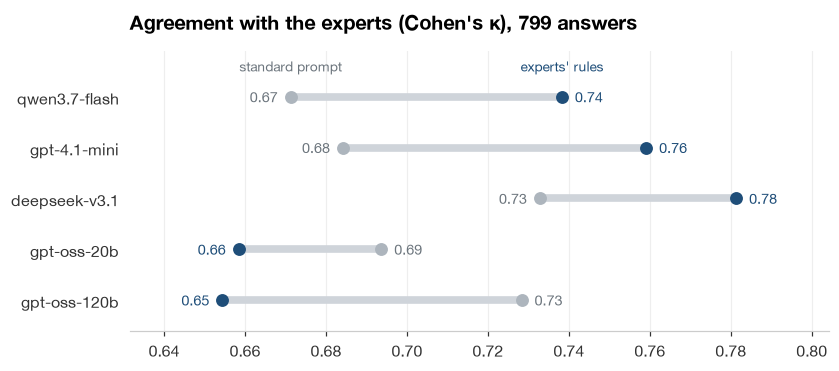

In [9]:
import matplotlib as mpl
import matplotlib.pyplot as plt
NAVY, SILVER, SLATE, LINK, REF = "#1f4e79", "#adb5bd", "#6c757d", "#cfd4da", "#555555"
mpl.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Inter", "Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
                     "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 14,
                     "axes.edgecolor": "#cccccc", "axes.labelcolor": "#333333", "xtick.color": "#333333", "ytick.color": "#333333",
                     "axes.grid": True, "axes.grid.axis": "x", "grid.color": "#eeeeee", "axes.axisbelow": True, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.spines.left": False, "ytick.left": False, "figure.dpi": 110, "savefig.dpi": 160})
Y = np.arange(len(ORDER))[::-1]   # most lenient judge on top

def dumbbell(ax, a, b, fmt, names=("standard prompt", "experts' rules")):
    # grey dot for the standard prompt, navy for the rules, joined by a bar; each value labelled on its outer side
    ax.hlines(Y, a, b, color=LINK, lw=5, zorder=1)
    ax.scatter(a, Y, s=55, color=SILVER, zorder=3); ax.scatter(b, Y, s=55, color=NAVY, zorder=3)
    span = max(max(a), max(b)) - min(min(a), min(b)); pad = 0.025 * span
    for y, x0, x1 in zip(Y, a, b):
        for x, col, other in ((x0, SLATE, x1), (x1, NAVY, x0)):
            ax.text(x + (pad if x >= other else -pad), y, fmt.format(x), ha="left" if x >= other else "right", va="center", fontsize=9.5, color=col)
    top = Y.max()
    if abs(b[0] - a[0]) < 0.3 * span:   # close dots: name each on its outer side so the names do not collide
        ha0, ha1 = ("right", "left") if a[0] <= b[0] else ("left", "right")
    else:
        ha0 = ha1 = "center"
    ax.text(a[0], top + 0.5, names[0], ha=ha0, fontsize=9, color=SLATE); ax.text(b[0], top + 0.5, names[1], ha=ha1, fontsize=9, color=NAVY)
    ax.set_yticks(Y); ax.set_yticklabels(ORDER); ax.set_ylim(-0.6, top + 0.9)
    lo, hi = min(min(a), min(b)), max(max(a), max(b)); ax.set_xlim(lo - 0.18 * span, hi + 0.18 * span)

def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white"); plt.show()

kap = {a: [A["cells"][f"{j}|{a}"]["kappa"][0] for j in ORDER] for a in ("STD", "GUIDE")}
fig, ax = plt.subplots(figsize=(8.2, 3.3))
dumbbell(ax, kap["STD"], kap["GUIDE"], "{:.2f}")
ax.set_title(f"Agreement with the experts (Cohen's κ), {A['n_items']} answers")
save(fig, "agreement_by_judge.png")

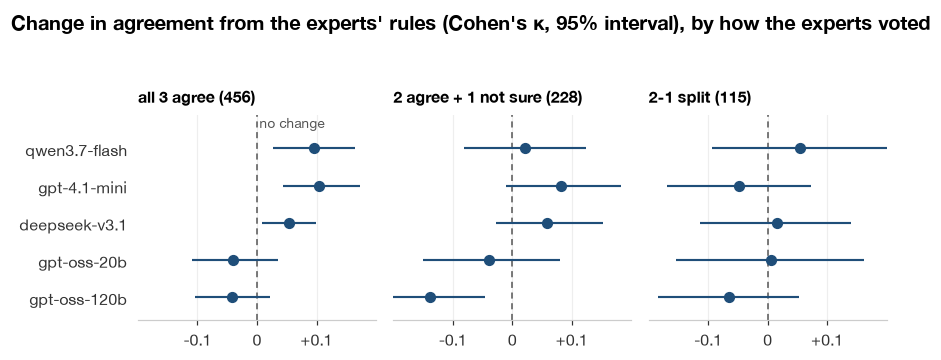

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(8.2, 3.3), sharey=True)
for k, (ax, g) in enumerate(zip(axes, GROUPS)):
    d = [A["deltas_by_group"][f"{j}|GUIDE-STD"][g] for j in ORDER]
    ax.axvline(0, color=REF, lw=1, ls=(0, (4, 3)), zorder=1)
    ax.hlines(Y, [x[1] for x in d], [x[2] for x in d], color=NAVY, lw=1.4, zorder=2)
    ax.scatter([x[0] for x in d], Y, s=40, color=NAVY, zorder=3)
    ax.set_title(f"{GROUPS[g]} ({A['groups'][g]})", fontsize=10.5, fontweight="bold", pad=8)
    ax.set_xlim(-0.2, 0.2); ax.set_xticks([-0.1, 0, 0.1]); ax.set_xticklabels(["-0.1", "0", "+0.1"])
    if k == 0: ax.text(0.004, Y.max() + 0.55, "no change", fontsize=9, color=REF)
axes[0].set_yticks(Y); axes[0].set_yticklabels(ORDER); axes[0].set_ylim(-0.6, Y.max() + 0.9)
fig.suptitle("Change in agreement from the experts' rules (Cohen's κ, 95% interval), by how the experts voted", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "agreement_change_by_vote_group.png")

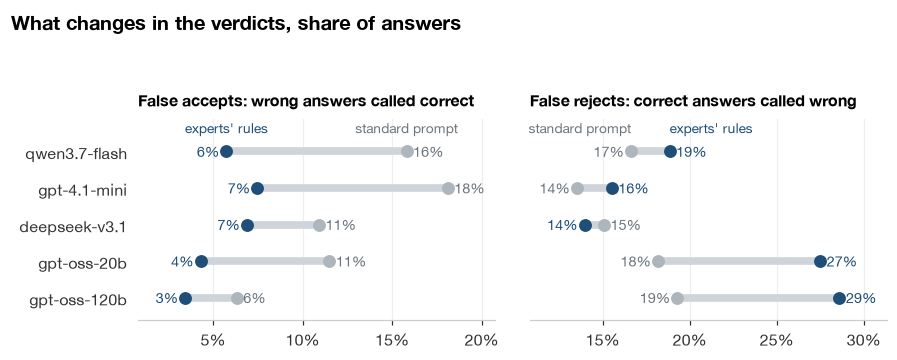

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.3), sharey=True)
for ax, (col, title) in zip(axes, [("fpr", "False accepts: wrong answers called correct"), ("fnr", "False rejects: correct answers called wrong")]):
    a, b = ([A["cells"][f"{j}|{p}"][col] * 100 for j in ORDER] for p in ("STD", "GUIDE"))
    dumbbell(ax, a, b, "{:.0f}%")
    ax.set_title(title, fontsize=10.5, pad=8); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
fig.suptitle("What changes in the verdicts, share of answers", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
save(fig, "false_accepts_and_rejects.png")

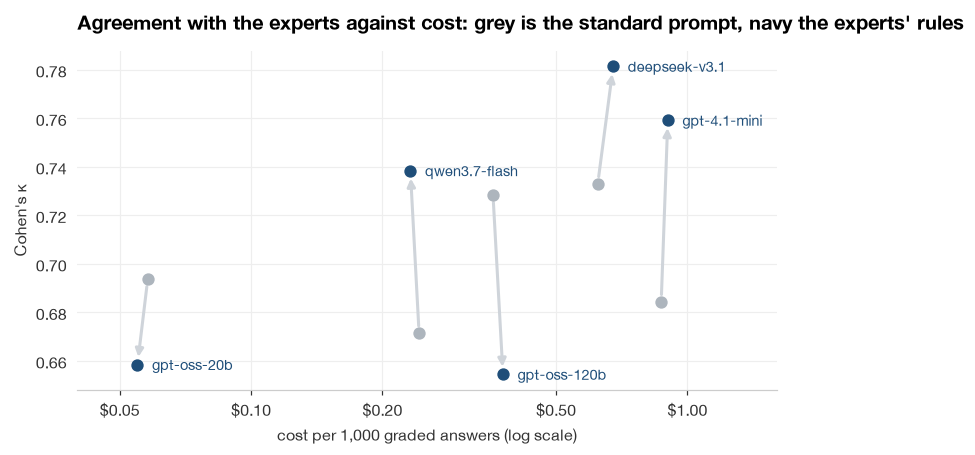

In [12]:
fig, ax = plt.subplots(figsize=(8.2, 4.0))
for j in ORDER:
    (x0, y0), (x1, y1) = ((cost(j, a) * 1000, A["cells"][f"{j}|{a}"]["kappa"][0]) for a in ("STD", "GUIDE"))
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=LINK, lw=2, shrinkA=5, shrinkB=5), zorder=1)
    ax.scatter([x0], [y0], s=50, color=SILVER, zorder=3); ax.scatter([x1], [y1], s=50, color=NAVY, zorder=3)
    ax.text(x1 * 1.08, y1, j, va="center", fontsize=9.5, color=NAVY)
ax.set_xscale("log"); ax.set_xticks([0.05, 0.1, 0.2, 0.5, 1.0]); ax.set_xticklabels(["$0.05", "$0.10", "$0.20", "$0.50", "$1.00"])
ax.minorticks_off(); ax.grid(axis="y", color="#eeeeee"); ax.set_xlim(0.04, 1.6)
ax.set_xlabel("cost per 1,000 graded answers (log scale)"); ax.set_ylabel("Cohen's κ")
ax.set_title("Agreement with the experts against cost: grey is the standard prompt, navy the experts' rules")
save(fig, "agreement_against_cost.png")

## What the results say

- **The rules help three of five judges.** qwen3.7-flash, gpt-4.1-mini and deepseek-v3.1 gain 0.049 to 0.075 in κ, mostly by accepting fewer wrong answers. The gains are clearest on the 456 answers all three experts agreed on.
- **A cheap judge can match the best one.** qwen3.7-flash with the rules reaches 0.74, against 0.73 for deepseek-v3.1 on the standard prompt, at $0.23 against $0.62 per 1,000 answers.
- **The rules hurt gpt-oss.** Both gpt-oss judges reject correct answers over one detail that differs from the reference. Without rule 2 they only return to their standard-prompt agreement.